# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [2]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [3]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [4]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

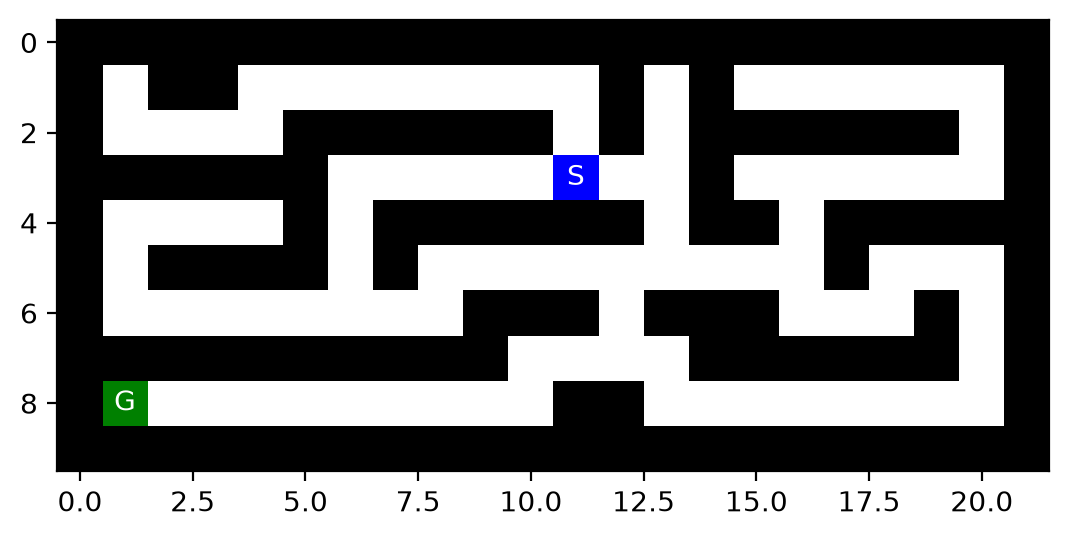

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [8]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [9]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'E', 'E', 'W', 'E', 'E', 'N', 'N', 'E', 'E']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [10]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: S
Following plan... step 1: N
Following plan... step 2: E
Following plan... step 3: S
Following plan... step 4: W
Following plan... step 5: E
Following plan... step 6: N
Following plan... step 7: N
Following plan... step 8: S
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [11]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

**Answer**: The agent knows the whole map, so the environment is fully observable, discrete, deterministic and known.

Initial state: the square that holds `S`, written as a `(row, col)` tuple.

Actions: the four moves `N`, `E`, `S`, `W`, with offsets `(-1,0)`, `(0,1)`, `(1,0)`, `(0,-1)`. A move is legal when the target square is inside the grid and is not a wall.

Transition model: `Result(s, a) = s + offset(a)`, and it is deterministic because the same state and action always give the same successor.

Goal state: the square that holds `G`. The goal test is `s == (r_G, c_G)`.

Path cost: every step costs 1, so the cost of a path is its number of moves and `g(n)` is the depth of node `n` in the search tree.

Since every move has an inverse with the same cost, the state graph is undirected and contains cycles.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**Answer**: `n` (state space size) is the number of squares that are not walls: count the rows times the columns and subtract the `X` squares. For the small maze that is 94.

`d` (depth of the optimal solution) is measured, not guessed: run BFS and read the path cost. The lower bound is the Manhattan distance between `S` and `G`.

`m` (maximum depth of the search tree) is measured by the search itself. A search with cycle checking can never exceed `n`, because a simple path visits each state at most once.

`b` (maximum branching factor) is at most 4, since only four moves exist. Counting the legal moves of each square gives 4 inside the maze, 3 on an edge, 2 in a corner and 1 in a dead end.

Measured state space sizes:

| maze | grid | n | b_max |
|---|---|---|---|
| small | 10x22 | 94 | 4 |
| medium | 18x36 | 274 | 4 |
| large | 37x37 | 647 | 4 |
| L | 15x15 | 157 | 4 |
| loops | 12x12 | 72 | 4 |
| open | 23x37 | 684 | 4 |
| empty | 12x12 | 100 | 4 |
| empty_2 | 12x12 | 100 | 4 |

The values of `d` and `m` for each maze are in the table of Task 4, since they come from the runs.

## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [12]:
import random
import sys
import time
from collections import deque

ACTIONS = ("N", "E", "S", "W")
DIRS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}
sys.setrecursionlimit(5000)


def new_metrics():
    # counters reported for every search
    return {"expanded": 0, "max_depth": 0, "max_frontier": 0, "max_memory": 0, "limit": None}


def transition(maze, pos, action):
    """Successor of pos for action, or None when it leaves the grid or hits a wall."""
    r, c = pos
    dr, dc = DIRS[action]
    nr, nc = r + dr, c + dc
    if 0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1] and maze[nr, nc] != "X":
        return (nr, nc)
    return None


def legal_actions(maze, pos, order=ACTIONS):
    return [a for a in order if transition(maze, pos, a) is not None]


def bfs(maze, start, goal, node_limit=float("inf"), time_limit=float("inf")):
    """BFS: FIFO frontier, `reached` prevents repeated states."""
    metrics = new_metrics()
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)
    t0 = time.perf_counter()

    root = Node(start, None, None, 0)
    if start == goal:
        return root, metrics

    frontier = deque([root])
    reached = {start}

    while frontier:
        if metrics["expanded"] >= node_limit or time.perf_counter() - t0 > time_limit:
            metrics["limit"] = "node/time budget"
            return None, metrics

        node = frontier.popleft()
        metrics["expanded"] += 1

        for action in legal_actions(maze, node.pos):
            child = Node(transition(maze, node.pos, action), node, action, node.cost + 1)
            if child.pos in reached:
                continue
            if child.pos == goal:
                metrics["max_depth"] = max(metrics["max_depth"], child.cost)
                metrics["max_frontier"] = max(metrics["max_frontier"], len(frontier))
                metrics["max_memory"] = max(metrics["max_memory"], len(frontier) + len(reached))
                return child, metrics
            reached.add(child.pos)
            frontier.append(child)
            metrics["max_depth"] = max(metrics["max_depth"], child.cost)

        metrics["max_frontier"] = max(metrics["max_frontier"], len(frontier))
        metrics["max_memory"] = max(metrics["max_memory"], len(frontier) + len(reached))

    return None, metrics


def dfs(maze, start, goal, node_limit=float("inf"), time_limit=float("inf"),
        action_order=None, rng=None):
    """DFS without a reached set. The only test against cycles is whether the
    successor is already on the current path (`on_path`). Subtrees are released
    when they are left, which keeps the memory at O(b*m)."""
    metrics = new_metrics()
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)
    t0 = time.perf_counter()
    rng = rng or random

    root = Node(start, None, None, 0)
    if start == goal:
        return root, metrics

    on_path = {start}

    def expand(node):
        if metrics["expanded"] >= node_limit or time.perf_counter() - t0 > time_limit:
            metrics["limit"] = "node/time budget"
            return None
        metrics["expanded"] += 1

        if action_order is None:
            actions = legal_actions(maze, node.pos)
            rng.shuffle(actions)
        else:
            actions = legal_actions(maze, node.pos, action_order)

        for i, action in enumerate(actions):
            child_pos = transition(maze, node.pos, action)
            if child_pos in on_path:
                continue
            child = Node(child_pos, node, action, node.cost + 1)
            metrics["max_depth"] = max(metrics["max_depth"], child.cost)
            metrics["max_frontier"] = max(metrics["max_frontier"], len(actions) - i)
            metrics["max_memory"] = max(metrics["max_memory"], child.cost + 1 + len(on_path))

            if child_pos == goal:
                return child
            on_path.add(child_pos)
            found = expand(child)
            on_path.discard(child_pos)
            if found is not None:
                return found
        return None

    return expand(root), metrics


def describe(node, metrics):
    if node is None:
        return "no solution ({}), expanded {}".format(metrics["limit"], metrics["expanded"])
    return "cost {}, expanded {}, max depth {}, max frontier {}".format(
        node.cost, metrics["expanded"], metrics["max_depth"], metrics["max_frontier"])


small = mh.parse_maze(open("small_maze.txt").read())
s = tuple(int(v) for v in mh.find_pos(small, "S"))
g = tuple(int(v) for v in mh.find_pos(small, "G"))

bfs_node, bfs_metrics = bfs(small, s, g)
dfs_node, dfs_metrics = dfs(small, s, g, action_order=ACTIONS)

print("small maze, start", s, "goal", g)
print("BFS:", describe(bfs_node, bfs_metrics))
print("DFS:", describe(dfs_node, dfs_metrics))
print("BFS actions:", [n.action for n in bfs_node.get_path_from_root()[1:]] if bfs_node else None)
print("DFS actions:", [n.action for n in dfs_node.get_path_from_root()[1:]] if dfs_node else None)

small maze, start (3, 11) goal (8, 1)
BFS: cost 19, expanded 90, max depth 19, max frontier 9
DFS: cost 37, expanded 93, max depth 44, max frontier 3
BFS actions: ['E', 'E', 'S', 'S', 'W', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']
DFS actions: ['E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

**Answer**: The maze graph is undirected, so every move can be undone and cycles always exist (a single corridor already contains the cycle north then south).

BFS keeps a `reached` set with every state it has generated. A successor that is already in `reached` is skipped, so no state is expanded twice and cycles cannot be re-entered. That is why BFS cannot loop, and the price is that `reached` has to store up to `n` states.

DFS without `reached` only compares the successor with the states on the current path. Here that set is `on_path`: a child is added when the search goes down into it, and removed when the whole subtree below it is finished. A successor found in `on_path` closes a cycle and is dropped. Since a simple path cannot repeat a state, the recursion depth is bounded by `n` and DFS terminates instead of looping forever, which it would otherwise do immediately in `loops_maze`.

The catch is that this test only forbids revisiting an ancestor. The same square can still be reached again through a different branch and be explored again, so on open terrain DFS may expand a very large number of nodes even though the tree is finite.

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

**Answer**: BFS is complete: the state space is finite and `reached` generates every state at most once, so a reachable goal is always found. It is optimal because every step costs 1 and the FIFO frontier expands nodes in order of increasing depth, so the goal is first reached along a shortest path. Its time is O(b^d), where b is the branching factor and d the depth of the optimal solution, and its space is O(b^d) as well because the frontier holds roughly a whole level and `reached` holds every generated state. Space is the real limit.

DFS is complete only because the state space is finite and cycle checking along the path prevents infinite descent; without that test the undirected graph would make it loop forever. It is not optimal, because it returns the first goal it reaches and the result depends on the order in which successors are generated. Its time is O(b^m) with m the maximum depth, and with cycle checking m is at most n. Its space is O(b*m): only the current path and the not yet tried actions are kept, and everything below an abandoned branch is released.

So the difference in space is O(b^d) against O(b*m). For b = 4, d = 20 and m = 50 that is about 10^12 nodes against a few hundred, which is why DFS is used when memory is the binding constraint.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [13]:
import heapq
import math


def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2)


def best_first(maze, start, goal, priority, heuristic, node_limit=float("inf"),
               time_limit=float("inf")):
    """Best-first graph search. priority is "h" for GBFS and "g+h" for A*."""
    metrics = new_metrics()
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)
    t0 = time.perf_counter()
    counter = 0

    def key(node):
        h = heuristic(node.pos, goal)
        return h if priority == "h" else node.cost + h

    root = Node(start, None, None, 0)
    frontier = [(key(root), counter, root)]
    reached = {start: 0}

    while frontier:
        if metrics["expanded"] >= node_limit or time.perf_counter() - t0 > time_limit:
            metrics["limit"] = "node/time budget"
            return None, metrics

        _, _, node = heapq.heappop(frontier)
        metrics["expanded"] += 1

        if node.pos == goal:
            metrics["max_depth"] = max(metrics["max_depth"], node.cost)
            metrics["max_memory"] = max(metrics["max_memory"], len(frontier) + len(reached))
            return node, metrics

        for action in legal_actions(maze, node.pos):
            child = Node(transition(maze, node.pos, action), node, action, node.cost + 1)
            best = reached.get(child.pos)
            if best is not None and best <= child.cost:
                continue
            reached[child.pos] = child.cost
            counter += 1
            heapq.heappush(frontier, (key(child), counter, child))
            metrics["max_depth"] = max(metrics["max_depth"], child.cost)

        metrics["max_frontier"] = max(metrics["max_frontier"], len(frontier))
        metrics["max_memory"] = max(metrics["max_memory"], len(frontier) + len(reached))

    return None, metrics


def gbfs(maze, start, goal, heuristic=manhattan, **kwargs):
    return best_first(maze, start, goal, "h", heuristic, **kwargs)


def astar(maze, start, goal, heuristic=manhattan, **kwargs):
    return best_first(maze, start, goal, "g+h", heuristic, **kwargs)


for name, run in (("GBFS Manhattan", lambda: gbfs(small, s, g)),
                  ("A* Manhattan", lambda: astar(small, s, g, manhattan)),
                  ("A* Euclidean", lambda: astar(small, s, g, euclidean))):
    node, metrics = run()
    print(name + ":", describe(node, metrics))

GBFS Manhattan: cost 29, expanded 40, max depth 29, max frontier 5
A* Manhattan: cost 19, expanded 54, max depth 19, max frontier 8
A* Euclidean: cost 19, expanded 57, max depth 19, max frontier 7


Are your implementations complete and optimal? What is the time and space complexity?

**Answer**: Both are complete in this problem, because `reached` keeps the state space finite and no state is generated twice.

GBFS uses f(n) = h(n), so it ignores the cost paid so far and always moves towards whatever looks closest to the goal. That is why it is fast but not optimal: it can follow a wall away from the real detour and return a path that is clearly longer than the BFS path. In the runs it gave 29 instead of 19 on the small maze and 68 instead of 54 on the open maze.

A* uses f(n) = g(n) + h(n), so it counts both what was paid and what is estimated to remain. It is optimal when h is admissible, meaning h(n) never overestimates the true remaining cost, and consistent, meaning h(n) <= cost(n,a,n') + h(n'). Manhattan satisfies both on a four-direction grid with unit costs, and the runs confirm it: A* returned the same cost as BFS on all eight mazes. Its time and space are still O(b^d) in the worst case, but the constant depends on the heuristic. With h = 0 A* becomes BFS, and with a perfect h it only expands the optimal path.

Euclidean is also admissible but weaker than Manhattan here, because a straight line always underestimates the number of axis-parallel steps, so A* with Euclidean expanded slightly more nodes on every maze.

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [14]:
import math
import os
import random
import time
import matplotlib.pyplot as plt

MAZE_FILES = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt",
              "loops_maze.txt", "open_maze.txt", "empty_maze.txt", "empty_maze_2.txt"]

NODE_BUDGET = 400000      # a search that needs more nodes gives up
TIME_BUDGET = 30.0        # seconds per run
DFS_RUNS = 5              # DFS depends on the order of the successors
SEED = 2024


def label(name):
    return name.replace("_maze", "").replace(".txt", "")


def load_mazes():
    loaded = {}
    for name in MAZE_FILES:
        maze = mh.parse_maze(open(name).read())
        start = tuple(int(v) for v in mh.find_pos(maze, "S"))
        goal = tuple(int(v) for v in mh.find_pos(maze, "G"))
        loaded[name] = (maze, start, goal)
    return loaded


def run_experiments():
    rows = []
    for name, (maze, start, goal) in load_mazes().items():
        runs = [("BFS", lambda: bfs(maze, start, goal, NODE_BUDGET, TIME_BUDGET)),
                ("GBFS", lambda: gbfs(maze, start, goal, manhattan,
                                      node_limit=NODE_BUDGET, time_limit=TIME_BUDGET)),
                ("A*", lambda: astar(maze, start, goal, manhattan,
                                     node_limit=NODE_BUDGET, time_limit=TIME_BUDGET)),
                ("A* (Euclid)", lambda: astar(maze, start, goal, euclidean,
                                              node_limit=NODE_BUDGET, time_limit=TIME_BUDGET))]

        for name_algo, run in runs:
            t0 = time.perf_counter()
            node, metrics = run()
            rows.append({"maze": label(name), "algorithm": name_algo,
                         "path cost": node.cost if node else "N/A",
                         "expanded": metrics["expanded"],
                         "max depth": metrics["max_depth"],
                         "max memory": metrics["max_memory"],
                         "max frontier": metrics["max_frontier"],
                         "sec": round(time.perf_counter() - t0, 3),
                         "actions": [n.action for n in node.get_path_from_root()[1:]] if node else [],
                         "note": metrics["limit"] or ""})

        # the seeded RNG is reset per maze so that repeated runs give the same table
        rng = random.Random(SEED)
        dfs_runs = []
        for _ in range(DFS_RUNS):
            t0 = time.perf_counter()
            node, metrics = dfs(maze, start, goal, NODE_BUDGET, TIME_BUDGET, rng=rng)
            dfs_runs.append({"maze": label(name), "algorithm": "DFS",
                             "path cost": node.cost if node else "N/A",
                             "expanded": metrics["expanded"],
                             "max depth": metrics["max_depth"],
                             "max memory": metrics["max_memory"],
                             "max frontier": metrics["max_frontier"],
                             "sec": round(time.perf_counter() - t0, 3),
                             "actions": [n.action for n in node.get_path_from_root()[1:]] if node else [],
                             "note": metrics["limit"] or ""})

        solved = [r for r in dfs_runs if r["path cost"] != "N/A"]
        if solved:
            # one row with all numbers from the same run
            chosen = dict(solved[0])
            chosen["note"] = ("run 1 of {} random orders".format(DFS_RUNS)
                              + ("" if len(solved) == len(dfs_runs)
                                 else ", {} run(s) hit the budget".format(len(dfs_runs) - len(solved))))
        else:
            chosen = dict(dfs_runs[0])
            chosen["sec"] = round(sum(r["sec"] for r in dfs_runs), 3)
            chosen["note"] = "no run finished ({})".format(dfs_runs[0]["note"])
        rows.append(chosen)

        rows.append({"maze": label(name), "algorithm": "DFS (range)",
                     "path cost": "{}-{}".format(min(r["path cost"] for r in solved),
                                                 max(r["path cost"] for r in solved)) if solved else "N/A",
                     "expanded": "{}-{}".format(min(r["expanded"] for r in dfs_runs),
                                                max(r["expanded"] for r in dfs_runs)),
                     "max depth": "{}-{}".format(min(r["max depth"] for r in dfs_runs),
                                                 max(r["max depth"] for r in dfs_runs)),
                     "max memory": "{}-{}".format(min(r["max memory"] for r in dfs_runs),
                                                  max(r["max memory"] for r in dfs_runs)),
                     "max frontier": "{}-{}".format(min(r["max frontier"] for r in dfs_runs),
                                                    max(r["max frontier"] for r in dfs_runs)),
                     "sec": round(sum(r["sec"] for r in dfs_runs), 3),
                     "actions": [],
                     "note": "min-max over {} runs".format(DFS_RUNS)})
    return rows


results = run_experiments()

header = "{:<13}{:>10}{:>10}{:>11}{:>12}{:>14}{:>9}".format(
    "algorithm", "path cost", "expanded", "max depth", "max memory", "max frontier", "sec")
for maze in dict.fromkeys(r["maze"] for r in results):
    print("\n" + maze)
    print(header)
    for r in results:
        if r["maze"] == maze:
            print("{:<13}{:>10}{:>10}{:>11}{:>12}{:>14}{:>9}".format(
                r["algorithm"], r["path cost"], r["expanded"], r["max depth"],
                r["max memory"], r["max frontier"], r["sec"]))

print("\npath costs found per maze:")
for maze in dict.fromkeys(r["maze"] for r in results):
    costs = {r["algorithm"]: r["path cost"] for r in results if r["maze"] == maze}
    print("  {:<9} BFS={}  DFS={}  GBFS={}  A*={}  A*(Euclid)={}".format(
        maze, costs["BFS"], costs["DFS"], costs["GBFS"], costs["A*"], costs["A* (Euclid)"]))


small
algorithm     path cost  expanded  max depth  max memory  max frontier      sec
BFS                  19        90         19          95             9    0.001
GBFS                 29        40         29          49             5      0.0
A*                   19        54         19          66             8      0.0
A* (Euclid)          19        57         19          66             7      0.0
DFS                  49        65         49          99             3      0.0
DFS (range)       19-49     19-65      19-49       39-99           3-3      0.0

medium
algorithm     path cost  expanded  max depth  max memory  max frontier      sec
BFS                  68       267         68         272             9    0.001
GBFS                 74        79         74          86             4      0.0
A*                   68       223         68         235             8    0.001
A* (Euclid)          68       227         68         236             8    0.001
DFS                  74  

Complete the following table for each maze.

__Small maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 19        | 90             | 19             | 95            | 9                 |
| DFS       | 49        | 65             | 49             | 99            | 3                 |
| GBS       | 29        | 40             | 29             | 49            | 5                 |
| A*        | 19        | 54             | 19             | 66            | 8                 |

__Medium Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 68        | 267            | 68             | 272           | 9                 |
| DFS       | 74        | 76             | 74             | 149           | 3                 |
| GBS       | 74        | 79             | 74             | 86            | 4                 |
| A*        | 68        | 223            | 68             | 235           | 8                 |

__Large Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 210       | 618            | 210            | 625           | 8                 |
| DFS       | 210       | 529            | 222            | 445           | 4                 |
| GBS       | 210       | 467            | 210            | 508           | 21                |
| A*        | 210       | 550            | 210            | 565           | 12                |

__L Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 16        | 146            | 16             | 156           | 17                |
| DFS       | 102       | 109            | 102            | 205           | 4                 |
| GBS       | 24        | 50             | 24             | 90            | 31                |
| A*        | 16        | 54             | 16             | 105           | 26                |

__Loops Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 23        | 70             | 23             | 73            | 8                 |
| DFS       | 43        | 43             | 43             | 87            | 3                 |
| GBS       | 23        | 77             | 23             | 71            | 10                |
| A*        | 23        | 60             | 23             | 67            | 6                 |

__Open Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 54        | 679            | 54             | 687           | 25                |
| DFS       | 140       | 400000         | 268            | 537           | 4                 |
| GBS       | 68        | 90             | 68             | 221           | 66                |
| A*        | 54        | 536            | 54             | 576           | 25                |

__Empty Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 14        | 92             | 14             | 99            | 12                |
| DFS       | 44        | 110            | 44             | 89            | 4                 |
| GBS       | 14        | 15             | 14             | 72            | 29                |
| A*        | 14        | 64             | 14             | 125           | 31                |

__Empty Maze (rotated)__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       | 14        | 92             | 14             | 99            | 11                |
| DFS       | 50        | 360            | 58             | 117           | 4                 |
| GBS       | 14        | 15             | 14             | 72            | 29                |
| A*        | 14        | 64             | 14             | 125           | 31                |

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

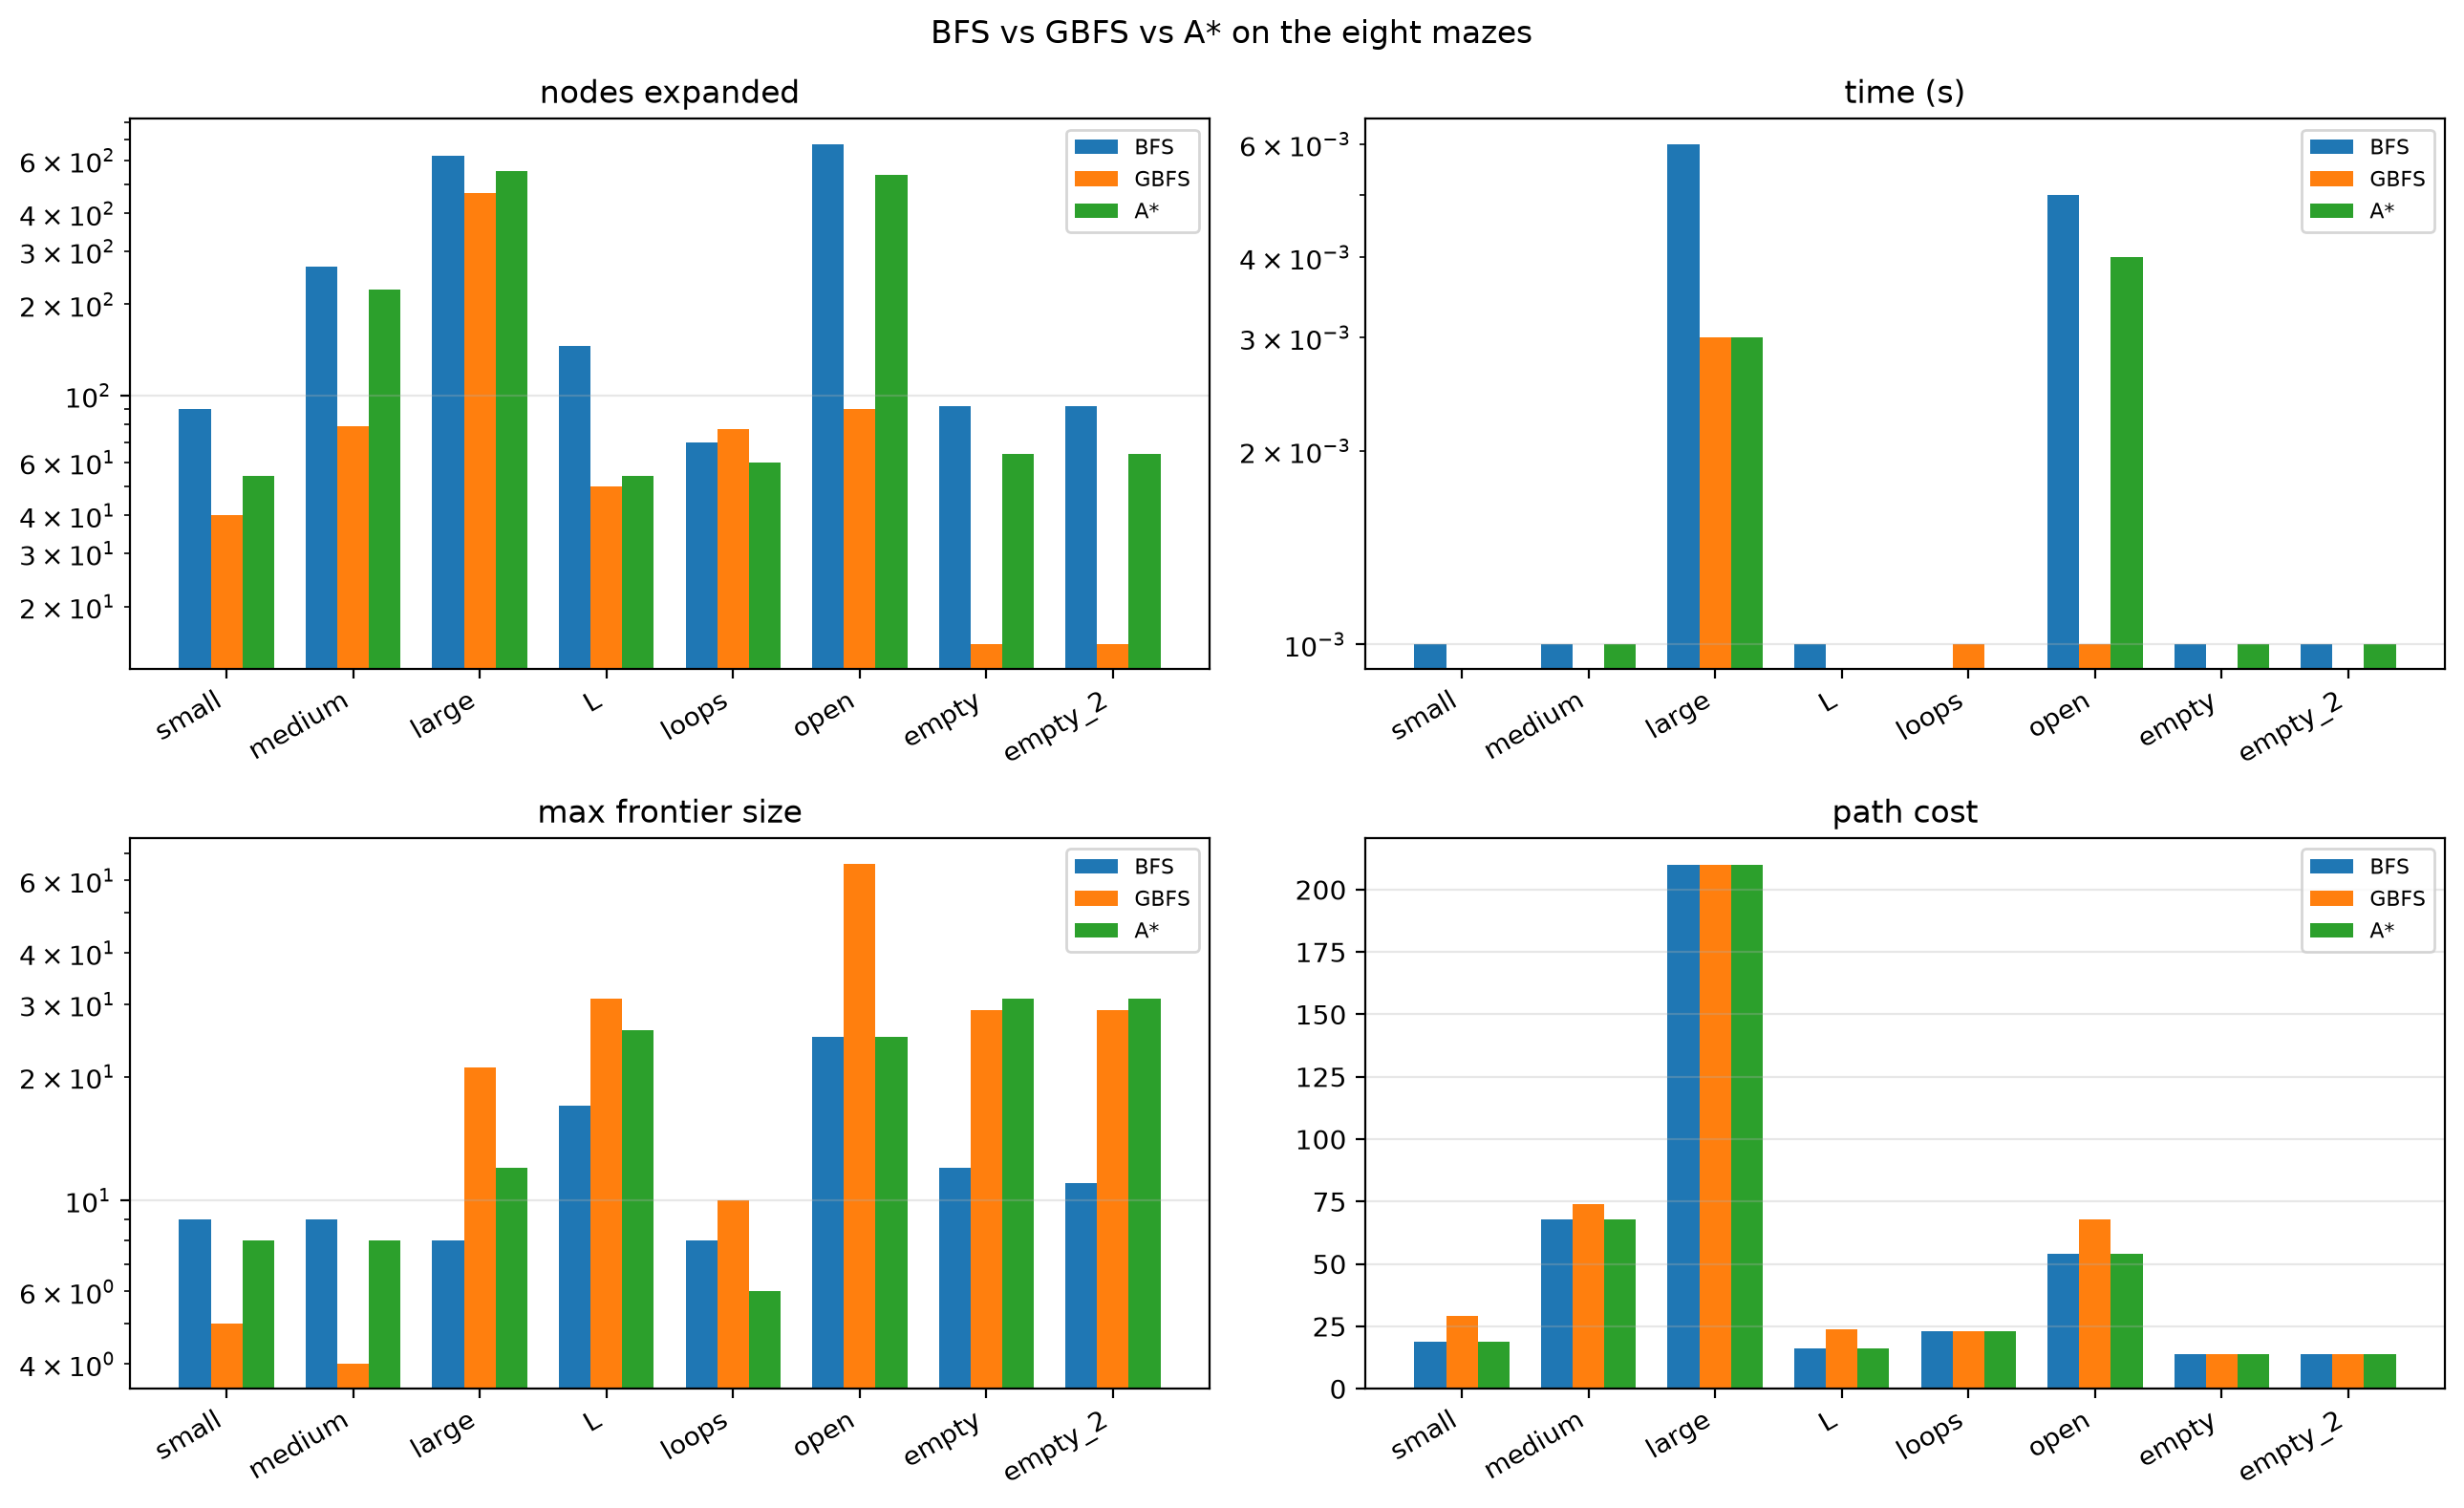

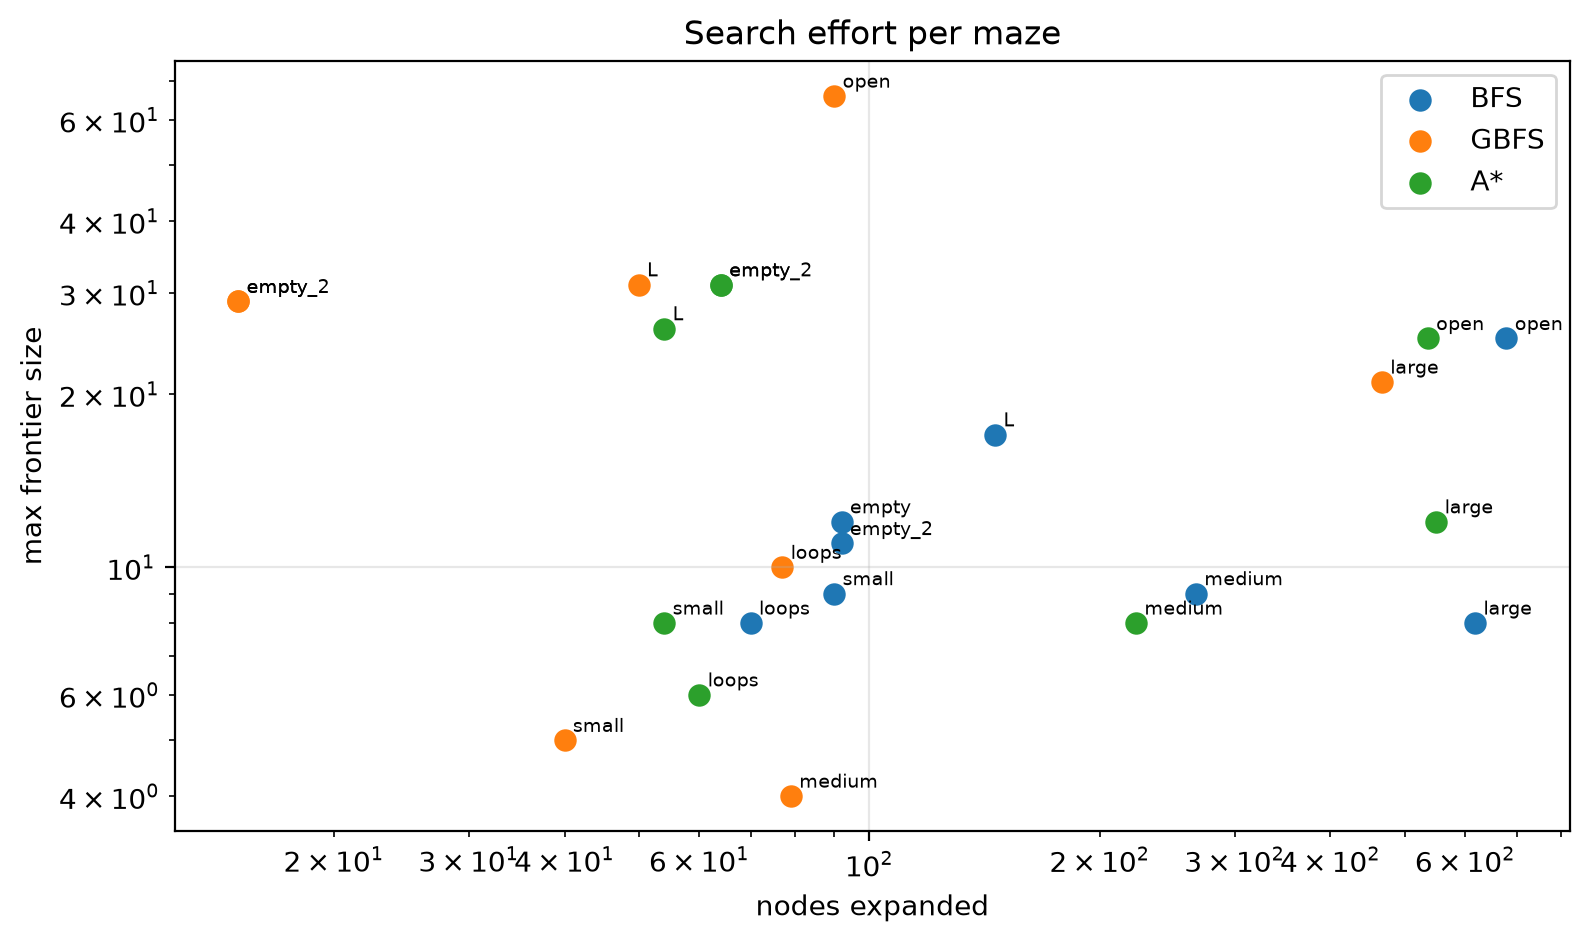

DFS is not plotted: its numbers are not comparable when it hits the node budget.


In [15]:
maze_labels = list(dict.fromkeys(r["maze"] for r in results))
plot_algos = ["BFS", "GBFS", "A*"]


def column(metric, algorithm):
    """Metric of one algorithm for every maze, in maze order."""
    values = []
    for maze in maze_labels:
        row = [r for r in results if r["maze"] == maze and r["algorithm"] == algorithm]
        value = row[0][metric] if row else "N/A"
        values.append(value if isinstance(value, (int, float)) else 1)
    return values


fig, axes = plt.subplots(2, 2, figsize=(13, 8))
width = 0.25
x = range(len(maze_labels))

for ax, metric, title, log in zip(axes.ravel(),
                                  ["expanded", "sec", "max frontier", "path cost"],
                                  ["nodes expanded", "time (s)", "max frontier size", "path cost"],
                                  [True, True, True, False]):
    for i, algorithm in enumerate(plot_algos):
        ax.bar([p + (i - 1) * width for p in x], column(metric, algorithm), width, label=algorithm)
    ax.set_xticks(list(x))
    ax.set_xticklabels(maze_labels, rotation=30, ha="right")
    ax.set_title(title)
    if log:
        ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("BFS vs GBFS vs A* on the eight mazes")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for algorithm in plot_algos:
    ax.scatter(column("expanded", algorithm), column("max frontier", algorithm),
               s=50, label=algorithm)
    for maze in maze_labels:
        row = [r for r in results if r["maze"] == maze and r["algorithm"] == algorithm]
        if row:
            ax.annotate(maze, (row[0]["expanded"], row[0]["max frontier"]),
                        fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("nodes expanded")
ax.set_ylabel("max frontier size")
ax.set_title("Search effort per maze")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("DFS is not plotted: its numbers are not comparable when it hits the node budget.")

Discuss the most important lessons you have learned from implementing the different search strategies. 

**Answer**: The frontier data structure is what separates the algorithms. BFS and DFS differ in one line, popping from the left or the right, plus the cycle checking that has to go with it. Writing DFS as BFS with a stack and keeping `reached` is a trap, because it keeps the memory of BFS without its optimality.

Cycle checking is mandatory for DFS. In this graph the immediate backtrack is already a cycle, and without the path test DFS never returns on `loops_maze`. The test must ask whether the successor is an ancestor, not whether it was seen before, since the latter is `reached`.

A heuristic changes how much of the maze is visited, not the answer. A* with Manhattan returned the same path cost as BFS on all eight mazes while expanding fewer nodes, and Euclidean was slightly worse than Manhattan because it underestimates the number of four-direction moves.

GBFS is the fastest but pays for it. It expanded only 15 nodes on the empty maze and 90 on the open maze, but its path was longer than the BFS path on five of the eight mazes.

DFS is the cheapest in memory and the worst in path quality. Its frontier stayed at 3 or 4 nodes, but it returned paths of 49, 102 and 140 moves where BFS needed 19, 16 and 54, and on the open maze it exhausted the 400000 node budget without finishing.

The measurements also show the limits of the theory. The bounds are asymptotic, while the tables show what actually happens per maze, including the cases where DFS or IDS cannot finish within a reasonable budget.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [16]:
def depth_limited_search(maze, start, goal, limit, metrics):
    """DFS that does not descend below `limit` squares."""
    on_path = {start}

    def expand(node):
        metrics["expanded"] += 1
        for action in legal_actions(maze, node.pos):
            child_pos = transition(maze, node.pos, action)
            if child_pos in on_path:
                continue
            child = Node(child_pos, node, action, node.cost + 1)
            if child_pos == goal:
                return child
            if child.cost >= limit:
                continue
            on_path.add(child_pos)
            found = expand(child)
            on_path.discard(child_pos)
            if found is not None:
                return found
        return None

    return expand(Node(start, None, None, 0))


def ids(maze, start, goal, node_limit=float("inf"), time_limit=float("inf")):
    """Iterative deepening: depth-limited DFS with limit = 0, 1, 2, ..."""
    metrics = new_metrics()
    t0 = time.perf_counter()

    for limit in range(1, 300):
        found = depth_limited_search(maze, start, goal, limit, metrics)
        metrics["max_depth"] = max(metrics["max_depth"], limit)
        metrics["max_frontier"] = max(metrics["max_frontier"], limit + 1)
        metrics["max_memory"] = max(metrics["max_memory"], limit + 1)
        if found is not None:
            metrics["rounds"] = limit
            return found, metrics
        if metrics["expanded"] > node_limit or time.perf_counter() - t0 > time_limit:
            metrics["limit"] = "budget exhausted at limit {}".format(limit)
            metrics["rounds"] = limit
            return None, metrics

    metrics["limit"] = "no solution below limit 300"
    return None, metrics


mazes = load_mazes()
header = "{:<10}{:>9}{:>11}{:>10}{:>8}".format("maze", "rounds", "path cost", "expanded", "sec")
print(header)
for name in ["small_maze.txt", "medium_maze.txt", "L_maze.txt", "loops_maze.txt"]:
    maze, start, goal = mazes[name]
    t0 = time.perf_counter()
    node, metrics = ids(maze, start, goal, node_limit=400000, time_limit=30.0)
    print("{:<10}{:>9}{:>11}{:>10}{:>8.2f}".format(
        label(name), metrics["rounds"], node.cost if node else "N/A",
        metrics["expanded"], time.perf_counter() - t0))

print()
print("IDS needs one round per depth level, so the number of rounds is d+1.")
print("The open and large mazes are not listed: every round re-expands the levels")
print("below it, and with many cycles the number of simple paths grows so fast that")
print("the 400000 node budget is used up long before the optimal depth is reached.")
print("On the L maze it stopped at limit 14 with 871232 nodes expanded and no path.")

maze         rounds  path cost  expanded     sec
small            19         19       923    0.00
medium           68         68     15429    0.08


L                14        N/A    871232    5.34


loops            23         23     78683    0.42

IDS needs one round per depth level, so the number of rounds is d+1.
The open and large mazes are not listed: every round re-expands the levels
below it, and with many cycles the number of simple paths grows so fast that
the 400000 node budget is used up long before the optimal depth is reached.
On the L maze it stopped at limit 14 with 871232 nodes expanded and no path.


### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [17]:
def add_goals(maze, positions):
    """Copy of the maze with extra G squares, the .txt files are not touched."""
    new_maze = np.copy(maze)
    for r, c in positions:
        if new_maze[r, c] == " ":
            new_maze[r, c] = "G"
    return new_maze


def goals_of(maze):
    return [tuple(int(v) for v in pos) for pos in zip(*np.where(maze == "G"))]


def search_any_goal(maze, start, algorithm, node_limit=400000, time_limit=30.0):
    """Run the algorithm once per goal and keep the cheapest solution."""
    best, best_metrics, best_goal = None, None, None
    for goal in goals_of(maze):
        node, metrics = algorithm(maze, start, goal, node_limit=node_limit, time_limit=time_limit)
        if node is not None and (best is None or node.cost < best.cost):
            best, best_metrics, best_goal = node, metrics, goal
    return best, best_metrics, best_goal


medium = mh.parse_maze(open("medium_maze.txt").read())
medium_start = tuple(int(v) for v in mh.find_pos(medium, "S"))
multi = add_goals(medium, [(8, 20), (5, 25)])
print("goals:", goals_of(multi))

rng = random.Random(SEED)
algorithms = [("BFS", lambda m, s, g, **kw: bfs(m, s, g, **kw)),
              ("A*", lambda m, s, g, **kw: astar(m, s, g, manhattan, **kw)),
              ("GBFS", lambda m, s, g, **kw: gbfs(m, s, g, manhattan, **kw)),
              ("DFS", lambda m, s, g, **kw: dfs(m, s, g, rng=rng, **kw)),
              ("IDS", lambda m, s, g, **kw: ids(m, s, g, node_limit=200000, time_limit=20.0))]

for name_algo, algorithm in algorithms:
    node, metrics, goal = search_any_goal(multi, medium_start, algorithm)
    print("{:<5} goal {}  cost {}  expanded {}".format(
        name_algo, goal, node.cost if node else "N/A",
        metrics["expanded"] if metrics else "N/A"))

print()
print("BFS and A* return the shortest path to the nearest goal, here 27 moves.")
print("DFS returned 125 moves and IDS returned 27 for the goal it finished first,")
print("so neither of them guarantees the nearest goal when it is called once per goal.")

goals: [(8, 20), (16, 1)]
BFS   goal (8, 20)  cost 27  expanded 71
A*    goal (8, 20)  cost 27  expanded 47
GBFS  goal (8, 20)  cost 27  expanded 77
DFS   goal (8, 20)  cost 125  expanded 143
IDS   goal (8, 20)  cost 27  expanded 874

BFS and A* return the shortest path to the nearest goal, here 27 moves.
DFS returned 125 moves and IDS returned 27 for the goal it finished first,
so neither of them guarantees the nearest goal when it is called once per goal.


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [18]:
import numpy as np

l_maze = mh.parse_maze(open("L_maze.txt").read())
walkable = int(np.sum(l_maze != "X"))


def degree(maze, pos):
    return len(legal_actions(maze, pos))


corners = [(r, c) for r in range(l_maze.shape[0]) for c in range(l_maze.shape[1])
           if l_maze[r, c] != "X" and (degree(l_maze, (r, c)) != 2 or l_maze[r, c] in "SG")]

print("L maze:", walkable, "walkable squares,", walkable - len(corners),
      "corridor squares with degree 2 and", len(corners), "decision points")
print()
print("Keeping only the decision points and the straight corridors as weighted")
print("edges shrinks the state space, but the edges then cost the number of squares")
print("they cover. With those different costs BFS and IDS no longer return the")
print("shortest path in squares. They have to be replaced by uniform-cost search,")
print("which is A* with h = 0, i.e. the best_first function with priority g+h and a")
print("heuristic that always returns 0.")

L maze: 157 walkable squares, 5 corridor squares with degree 2 and 152 decision points

Keeping only the decision points and the straight corridors as weighted
edges shrinks the state space, but the edges then cost the number of squares
they cover. With those different costs BFS and IDS no longer return the
shortest path in squares. They have to be replaced by uniform-cost search,
which is A* with h = 0, i.e. the best_first function with priority g+h and a
heuristic that always returns 0.


### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [19]:
def weighted_astar(maze, start, goal, weight, heuristic=manhattan,
                   node_limit=400000, time_limit=30.0):
    """A* with f = g + w*h."""
    metrics = new_metrics()
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)
    t0 = time.perf_counter()
    counter = 0

    root = Node(start, None, None, 0)
    frontier = [(weight * heuristic(start, goal), counter, root)]
    reached = {start: 0}

    while frontier:
        if metrics["expanded"] >= node_limit or time.perf_counter() - t0 > time_limit:
            metrics["limit"] = "node/time budget"
            return None, metrics

        _, _, node = heapq.heappop(frontier)
        metrics["expanded"] += 1

        if node.pos == goal:
            return node, metrics

        for action in legal_actions(maze, node.pos):
            child = Node(transition(maze, node.pos, action), node, action, node.cost + 1)
            best = reached.get(child.pos)
            if best is not None and best <= child.cost:
                continue
            reached[child.pos] = child.cost
            counter += 1
            heapq.heappush(frontier,
                           (child.cost + weight * heuristic(child.pos, goal), counter, child))
    return None, metrics


print("{:>5}{:>10}{:>11}{:>10}{:>8}".format("w", "maze", "path cost", "expanded", "sec"))
for name in ["medium_maze.txt", "large_maze.txt", "open_maze.txt"]:
    maze, start, goal = mazes[name]
    for weight in [0, 0.5, 1, 1.5, 2, 5, 10]:
        t0 = time.perf_counter()
        node, metrics = weighted_astar(maze, start, goal, weight)
        print("{:>5}{:>10}{:>11}{:>10}{:>8.3f}".format(
            weight, label(name), node.cost if node else "N/A", metrics["expanded"],
            time.perf_counter() - t0))

"""**Answer**: w = 1 is the normal A* and returns the optimal cost. Larger weights
make the heuristic matter more, so the search expands fewer nodes but the path gets
longer: on the open maze w = 2 returned 62 instead of 54 while expanding 217 instead
of 536 nodes. The cost stays within w times the optimal one."""

    w      maze  path cost  expanded     sec
    0    medium         68       270   0.002
  0.5    medium         68       244   0.001
    1    medium         68       223   0.001
  1.5    medium         68       231   0.001
    2    medium         68       231   0.001
    5    medium         74        79   0.000
   10    medium         74        79   0.000
    0     large        210       622   0.003
  0.5     large        210       599   0.003
    1     large        210       550   0.003
  1.5     large        210       523   0.003
    2     large        210       511   0.003
    5     large        210       496   0.003
   10     large        210       476   0.003
    0      open         54       683   0.005
  0.5      open         54       610   0.005
    1      open         54       536   0.004
  1.5      open         58       230   0.002
    2      open         62       217   0.002
    5      open         68        99   0.001
   10      open         68        92   0.001


'**Answer**: w = 1 is the normal A* and returns the optimal cost. Larger weights\nmake the heuristic matter more, so the search expands fewer nodes but the path gets\nlonger: on the open maze w = 2 returned 62 instead of 54 while expanding 217 instead\nof 536 nodes. The cost stays within w times the optimal one.'

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

**Answer**:

The agent does not know the transition function any more, so a plan made in
advance by BFS or A* is not valid: it was made for a map the agent cannot see.
The agent has to plan and act at the same time.

PEAS: the performance measure is reaching the goal with as few moves as
possible; the environment is a maze whose walls are only discovered by the
sensors, and it is sequential, deterministic, static and discrete; the actuators
are the four moves; the sensors give the current square and which of the four
neighbours are walls.

An agent that only sees its own square has to explore. The usual approach is an
online depth-first search: keep a map of what has been observed, move to a
neighbour whose outcome is still unknown while one exists, and when the current
square has no unexplored neighbour left, go back along the path to the nearest
square that still has one. Only the current path and the visited squares have to
be stored, so the memory stays linear. LRTA* is a refinement: it keeps a cost
estimate per visited square and updates it after every move, which avoids
repeating the same mistakes and converges to an optimal path in finite mazes.

If the agent also has a GPS, it can read a distance to the goal even for squares
it has not visited. That distance can be used as h in f = g + h, so the
exploration is guided towards the goal instead of wandering. The walls still
have to be discovered by moving, because the GPS only gives a distance and not
the layout.